# 05 问答系统：二层评论模型、批量查询与本地缓存


## 本章范围与资料来源

学习记录解决“学到了哪里”，互动问答解决“哪里不懂、谁来解答”。本章从课程详情页、视频学习页和管理端原型出发，设计问题、回答、评论的存储与接口，再实现跨服务的数据补齐。

| 来源 | 使用内容 |
| --- | --- |
| [网盘分享](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj)，提取码 `w7bj` | `day05-问答系统/讲义/day05-互动问答.pptx`，共 38 页；接口、两张表、回复流程 |
| [课程在线讲义：day05-问答系统](https://my.feishu.cn/wiki/wikcn6dq4McNdlfbbhdSeOdPbCe) | 产品规则、SQL、新增问题、用户端分页及详情、管理端分页、Caffeine，以及回复相关练习 |
| 网盘 `资料`目录 | 确认包含 `dto`、`enums`、`query`、`vo` 和 `tj_learning_question.sql`；未取得这些附件的完整源码，表结构与实现以已读 PPT、在线讲义为依据 |

学习路线：需求 → 二层回复模型 → 数据表 → 问题接口 → 批量补齐信息 → 管理端搜索与分类缓存 → 回复练习 → 匿名、隐藏与一致性。

**课件实现**指已读讲义中的关键片段或等价简化；**补充 / 改进示例**用于解释遗漏、完成练习或说明工程边界，不表示这些改进已经存在于课程代码。点赞操作在下一章展开，本章只保留点赞数量与展示需求。


## 产品流程与用户角色

课程讨论需要保留上下文，不能把问题当成一个与课程无关的聊天消息。每个问题关联课程，可进一步关联章、小节。

| 页面或角色 | 核心行为 | 规则 |
| --- | --- | --- |
| 学员课程详情页 | 全部问题 / 我的问题，提问、编辑、删除、查看详情 | 原型面向已登录且已购买课程的用户；课程固定，章节可选 |
| 视频学习页 | 围绕当前视频快速提问 | 默认查询当前小节，自动关联课程及章节 |
| 学员、老师 | 回答问题，评论回答，回复评论 | 支持匿名；页面只展示两层 |
| 管理端 | 条件筛选、查看、回答、隐藏或恢复内容 | 查看状态与用户端可见状态分开维护 |

```text
学员学习课程 → 提出问题 → 老师或其他学员回答
                              └→ 继续评论、回复评论
管理端查看与处理 ← 新的学员回复使问题重新进入待查看状态
```

**补充**：页面上有按钮不代表请求有权限。服务端应校验登录身份、课程学习资格和资源归属；编辑、删除只能操作自己的问题，管理操作需管理权限。


## 问题、回答、评论的二层模型

用户可以不断回复他人，但若页面逐层缩进，深层讨论会越来越难读。课程把回复统一存入一张表，界面只呈现“回答 + 回答下的评论”两层。

| 名称 | 回复对象 | 数据定位 |
| --- | --- | --- |
| 问题 Question | 针对课程提出疑问 | `interaction_question.id` |
| 回答 Answer | 直接回答问题 | 回复表中 `answer_id = 0` 的记录 |
| 评论 Comment | 回复某个回答或评论 | 回复表中 `answer_id` 指向所属一级回答 |

```text
问题 Q=100
├── 回答 A=201（张三）
│   ├── 评论 C=301（李四回复张三）
│   ├── 评论 C=302（王五回复李四，目标是301）
│   └── 评论 C=303（张三回复王五，目标是302）
└── 回答 A=202（老师）
    └── 评论 C=304（学员回复老师）
```

301、302、303 都展示在回答 201 的第二层。**逻辑上可以无限接续对话，显示层级仍然只有两层。**

> `answerId` 是评论所属的一级回答，不是上一条评论。若把它写成直接父评论 id，查询 `answer_id = 201` 就查不到 302、303。

这种模型适合课程讨论、文章评论。若产品需要完整的树形展示，则要设计父节点、路径或递归查询，不能直接照搬本模型。


## 回复关联字段：所属位置与对话目标

仅知道“在哪个回答下面”，无法展示“王五回复了李四”。因此评论还要记录它针对的具体回复与用户。

| 字段 | 回答 | 评论 | 作用 |
| --- | --- | --- | --- |
| `question_id` | 问题 id | 同一个问题 id | 所有回复都能追溯到问题 |
| `answer_id` | 0 | 一级回答 id | 将所有评论归入同一个第二层列表 |
| `target_reply_id` | 通常为 0 | 被回复的回答或评论 id | 表示直接对话目标 |
| `target_user_id` | 通常为 0 | 目标回复的作者 id | 补齐“回复了谁”的昵称 |
| `user_id` | 当前回答者 | 当前评论者 | 服务端从登录上下文获取 |

**补充示例**：沿用上一节的对话，统一用 0 表示“没有目标”。

| id | 类型 | question_id | answer_id | user_id | target_reply_id | target_user_id |
| --- | --- | --- | --- | --- | --- | --- |
| 201 | 张三回答 | 100 | 0 | 11 | 0 | 0 |
| 301 | 李四评论回答 | 100 | 201 | 12 | 201 | 11 |
| 302 | 王五回复评论301 | 100 | 201 | 13 | 301 | 12 |

“评论回答”时目标回复可以指向一级回答；如果项目约定省略该字段，也要在服务端规范化。**0、null 和省略参数不能混用而不处理**，否则回答判断与查询条件会不一致。


## 查看状态、隐藏状态与匿名状态

三个字段都像开关，但管理的事情不同。

| 字段 | 管理什么 | 状态变化 |
| --- | --- | --- |
| `status` | 管理员是否查看过问题及新互动 | 0 未查看；管理员查看变 1；新的学员回答或评论重置为 0 |
| `hidden` | 用户端是否可以看到内容 | false 显示；true 隐藏；管理端仍可管理 |
| `anonymity` | 用户端是否展示作者身份 | 匿名时隐藏作者 id、昵称、头像；数据库仍记录真实作者 |

```text
问题创建：UN_CHECK
    ↓ 管理员查看
CHECKED
    ↓ 学员新增回答或评论
UN_CHECK
```

**已查看不等于已解决**，它只是管理端的处理提示。老师自己回复时不应按“学员新互动”自动重置，角色判断需要可靠的身份来源。

隐藏问题会让其所有回答与评论在用户端不可见；隐藏一级回答会让它下面的评论不可见。匿名仅影响对外展示，不应取消作者的编辑、删除权限。


## 问答接口总览

课堂按 REST 风格将资源分为 `questions` 和 `replies`。下面是讲义明确设计的 12 个接口；服务内路径在表中列出，通过课程网关访问学习服务时加 `/ls` 前缀。

| 场景 | 方法与路径 | 核心参数或行为 |
| --- | --- | --- |
| 新增问题 | `POST /questions` | 标题、详情、课程与章节、是否匿名 |
| 修改我的问题 | `PUT /questions/{id}` | 修改标题、详情、匿名标记 |
| 用户端问题分页 | `GET /questions/page` | courseId / sectionId、onlyMine、分页 |
| 用户端问题详情 | `GET /questions/{id}` | 问题 id，过滤隐藏，处理匿名 |
| 删除我的问题 | `DELETE /questions/{id}` | 校验作者，同时删除下属回复 |
| 管理端问题分页 | `GET /admin/questions/page` | 课程名称、查看状态、提问时间范围 |
| 管理端问题详情 | `GET /admin/questions/{id}` | 补齐课程、章节等信息，标记已查看 |
| 管理端隐藏问题 | `PUT /admin/questions/{id}/hidden/{hidden}` | 更新用户端可见状态 |
| 新增回答或评论 | `POST /replies` | questionId、answerId、对话目标、内容 |
| 用户端回复分页 | `GET /replies/page` | questionId / answerId、分页 |
| 管理端回复分页 | `GET /admin/replies/page` | 返回隐藏内容和真实用户信息 |
| 管理端隐藏回复 | `PUT /admin/replies/{id}/hidden/{hidden}` | 若是回答，其评论也须不可见 |

讲义给出了新增问题、用户问题分页、用户问题详情、管理问题分页的实现。修改、删除、管理详情、隐藏，以及回答评论相关实现主要留作练习。

GET 查询参数应放在 URL 查询串中。讲义用带注释的 JSON 展示参数结构，不能直接把它当作合法 JSON 请求体。


## 问题表：基本信息与列表冗余字段

每次展示问题列表，如果再逐条统计回答数、找最新回答，查询成本会增大。课件在问题表中保存这些列表常用值，用写入时维护换取查询时便利。

| 字段 | 用途 |
| --- | --- |
| `id`、`title`、`description` | 问题标识、标题、富文本详情 |
| `course_id`、`chapter_id`、`section_id` | 学习上下文 |
| `user_id` | 提问者，匿名时仍保留 |
| `latest_answer_id` | 最新一级回答 id，列表展示回答预览 |
| `answer_times` | 一级回答数量，不包含二级评论 |
| `anonymity`、`hidden`、`status` | 匿名、可见性、管理查看状态 |
| `create_time`、`update_time` | 创建与更新时间 |

下面是**在线讲义 DDL 的结构整理**，省略逐列注释及重复排序规则：

```sql
CREATE TABLE interaction_question (
    id BIGINT NOT NULL,
    title VARCHAR(255) NOT NULL,
    description VARCHAR(2048) NOT NULL DEFAULT '',
    course_id BIGINT NOT NULL,
    chapter_id BIGINT NOT NULL,
    section_id BIGINT NOT NULL,
    user_id BIGINT NOT NULL,
    latest_answer_id BIGINT DEFAULT NULL,
    answer_times INT UNSIGNED NOT NULL DEFAULT 0,
    anonymity BIT(1) NOT NULL DEFAULT b'0',
    hidden BIT(1) NOT NULL DEFAULT b'0',
    status TINYINT DEFAULT 0,
    create_time DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP,
    update_time DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP
        ON UPDATE CURRENT_TIMESTAMP,
    PRIMARY KEY (id),
    KEY idx_course_id (course_id),
    KEY section_id (section_id),
    KEY user_id (user_id)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4
  COLLATE=utf8mb4_0900_ai_ci;
```

这属于**反范式**：把能由其他记录计算的数据存起来，减少读时计算。代价是新增、删除、隐藏回答时，都要考虑统计字段与最新回答指针是否仍然正确。


## 回复表：回答与评论共用存储

回答和评论共享内容、作者、匿名、点赞等属性，差异可由关联字段表示，课程将它们统一存入 `interaction_reply`。

```sql
-- 在线讲义 DDL 的结构整理
CREATE TABLE interaction_reply (
    id BIGINT NOT NULL,
    question_id BIGINT NOT NULL,
    answer_id BIGINT DEFAULT 0,
    user_id BIGINT NOT NULL,
    content VARCHAR(255) NOT NULL,
    target_user_id BIGINT DEFAULT 0,
    target_reply_id BIGINT DEFAULT 0,
    reply_times INT NOT NULL DEFAULT 0,
    liked_times INT NOT NULL DEFAULT 0,
    hidden BIT(1) NOT NULL DEFAULT b'0',
    anonymity BIT(1) NOT NULL DEFAULT b'0',
    create_time DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP,
    update_time DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP
        ON UPDATE CURRENT_TIMESTAMP,
    PRIMARY KEY (id),
    KEY idx_question_id (question_id)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4
  COLLATE=utf8mb4_0900_ai_ci;
```

| 字段 | 判断要点 |
| --- | --- |
| `answer_id` | 0 是一级回答；非 0 是所属回答下的评论 |
| `reply_times` | 一级回答下面的评论数量；二级评论无需展示它的子评论数 |
| `liked_times` | 当前回复的点赞总数，后续章节实现维护 |
| `hidden` | 当前记录自己的隐藏标记，用户可见性还受祖先影响 |

表中没有物理外键，问题、回答、目标回复之间的合法关系须由应用维护。对方内容被删除后，目标引用的展示策略也需明确，不能假定关联记录永远存在。


## 表结构中的边界与索引选择

产品允许课程详情页不选择章节，但课件的 `chapter_id`、`section_id` 是 `NOT NULL` 且没有默认值。这是材料中需要处理的差异。

| 边界 | 课件情况 | 补充建议 |
| --- | --- | --- |
| 可选章节 | 需求可不选，DDL 不允许 null | 明确允许 NULL 或统一用 0 表示未关联；DTO 和查询都按同一约定 |
| 回复层级 | answer_id 默认 0，但仍允许显式 null | 入参省略值统一归一化；必要时改为 NOT NULL DEFAULT 0 |
| 富文本长度 | description 2048，content 255 | 校验的是最终存储字符串；HTML 和图片 URL 也占长度，按产品需要评估 TEXT |
| 数据库版本 | `utf8mb4_0900_ai_ci` | 这是 MySQL 8 的排序规则，迁移到旧版本需调整 |
| 索引差异 | 在线问题 DDL 有 user_id 索引，PPT 第20页未列出 | 以实际数据库为准，不把两份材料当成完全相同 |

典型用户分页条件是“课程 / 小节 + hidden=false + create_time 排序”；回复分页是“question_id + answer_id + hidden + 排序”。

**补充索引示例**：

```sql
CREATE INDEX idx_question_course_visible_time
ON interaction_question (course_id, hidden, create_time, id);

CREATE INDEX idx_reply_answer_visible_time
ON interaction_reply (answer_id, hidden, create_time, id);
```

这里只表达按查询模式设计联合索引的方向。是否加索引、是否改为点赞排序索引，要结合数据量、`EXPLAIN` 执行计划与写成本，不能把示例索引直接当作万能配置。


## 代码分层、ID 与状态枚举

课件用 MyBatis-Plus 生成 PO、Mapper、Service、Controller，再把路径调整为资源名。自动生成能减少样板代码，不能替代权限和业务关系校验。

| 类型 | 作用 | 课程例子 |
| --- | --- | --- |
| DTO | 接收写入表单 | `QuestionFormDTO` |
| Query | 接收查询条件，复用分页参数 | `QuestionPageQuery extends PageQuery` |
| PO | 映射数据库记录 | `InteractionQuestion`、`InteractionReply` |
| VO | 返回页面所需信息 | `QuestionVO`、`QuestionAdminVO`、回复 VO |
| Feign Client | 调用其他微服务 | `UserClient`、`CourseClient`、`SearchClient` |

问题与回复 id 使用雪花算法；MyBatis-Plus 可按项目配置使用 `IdType.ASSIGN_ID`。雪花 ID 可在写库前生成，方便同一事务里把新回答 id 写入问题表。多实例需正确配置生成器，不能仅因采用雪花算法就忽略时钟和节点冲突。

**补充**：雪花 ID 通常超过 JavaScript 安全整数范围 `2^53-1`，对前端建议按字符串传输，后端再绑定为 Long。示例请求因此使用字符串 id。

```java
// 课件枚举的核心定义
@Getter
public enum QuestionStatus implements BaseEnum {
    UN_CHECK(0, "未查看"),
    CHECKED(1, "已查看");

    @JsonValue
    @EnumValue
    int value;
    String desc;

    QuestionStatus(int value, String desc) {
        this.value = value;
        this.desc = desc;
    }
}
```

`@EnumValue` 标明入库数值，`@JsonValue` 标明 JSON 序列化值；讲义用 `@JsonCreator` 将数字还原为枚举。讲义对未知数字返回 null，**补充**建议对非法状态给出明确参数错误。


## 新增问题：表单与课堂实现

提问时课程不可缺，登录用户由服务端确定；标题、描述和匿名选择来自表单。

```json
{
  "courseId": "100",
  "chapterId": "101",
  "sectionId": "102",
  "title": "JDK 去哪里下载？",
  "description": "课程中的下载地址在哪里？",
  "anonymity": false
}
```

课程详情页没有选择章节时，按项目统一约定省略或规范化对应字段，不直接把 null 写入课件的 NOT NULL 列。

```java
// 课件 Controller 关键代码
@RestController
@RequestMapping("/questions")
@RequiredArgsConstructor
public class InteractionQuestionController {
    private final IInteractionQuestionService questionService;

    @PostMapping
    public void saveQuestion(@Valid @RequestBody QuestionFormDTO dto) {
        questionService.saveQuestion(dto);
    }
}

// 课件 Service 关键代码
@Override
@Transactional
public void saveQuestion(QuestionFormDTO dto) {
    Long userId = UserContext.getUser();
    InteractionQuestion question = BeanUtils.toBean(dto, InteractionQuestion.class);
    question.setUserId(userId);
    save(question);
}
```

`@Valid` 触发表单校验，但只有 DTO 上配置了对应校验约束才会生效。**补充**需要检查标题非空、长度、章节是否属于课程、插入结果；`hidden`、`status`、计数等系统字段不应允许表单任意覆盖。

详情允许富文本与图片，提交到问答表的是内容或图片 URL，并不等于该接口本身负责上传文件。**补充**：富文本应按允许的标签、属性和 URL 协议处理，避免存储型 XSS，即保存后在其他用户页面执行脚本。


## 修改问题：字段白名单与作者权限

讲义将修改留作练习，定义 `PUT /questions/{id}`，主要修改标题、描述、是否匿名。路径 id 决定修改哪个问题。

```json
{
  "title": "JDK 17 的官方下载地址是什么？",
  "description": "想核对课程使用的版本。",
  "anonymity": true
}
```

**补充 / 练习实现思路**：查询存在性，验证作者；仅更新允许编辑的列，并在更新条件中保留作者约束。

```sql
UPDATE interaction_question
SET title = :title, description = :description, anonymity = :anonymity
WHERE id = :questionId AND user_id = :currentUserId;
```

根据受影响行数和先前查询结果决定返回不存在或无权编辑。不要把整个 DTO 直接覆盖 PO，导致 `user_id`、完成统计或隐藏状态被改掉。

**材料差异**：PPT 第9页的编辑参数表仍列了 courseId、chapterId、sectionId；在线讲义只给标题、描述、匿名标记。这里按在线修改契约整理。若实际前端允许更换章节，应显式定义并校验，不因 DTO 复用就默认允许。

新增要求 courseId，修改不携带它。若共用 DTO 并给 courseId 加了必填校验，要用校验分组或拆分 DTO，否则合法的修改请求会失败。


## 删除问题：同时处理下属回复

只删除问题行，会留下没有问题归属的回答和评论。讲义练习要求先检查问题存在及作者身份，再删除问题和其全部回复。

**补充 / 改进示例**：在数据库事务中锁定父问题，完成作者校验，再删回复与问题。

```sql
BEGIN;
SELECT id, user_id FROM interaction_question
WHERE id = :questionId FOR UPDATE;
-- 应用检查 user_id 等于当前用户

DELETE FROM interaction_reply WHERE question_id = :questionId;
DELETE FROM interaction_question
WHERE id = :questionId AND user_id = :currentUserId;
COMMIT;
```

课程原流程先删问题再删回复；同一事务内两种顺序都要考虑约束和竞争。上面先删子记录便于将来增加外键。

> 给删除加事务还不够：如果新增回复不遵守同一套父记录校验与锁定规则，删除期间仍可能插入新的孤儿回复。

回复新增与删除应共同协调父问题状态。若改用逻辑删除，所有查询都必须过滤删除标记，同时规定回复、点赞等相关数据的回收策略。点赞数据在后续实现后也要纳入清理。


## 用户端问题分页：查询条件与轻量字段

用户是在课程或视频中看讨论，不能不带范围就返回全部课程的问题。讲义要求 courseId 和 sectionId **至少提供一个**；两个都有时同时过滤。

```text
GET /ls/questions/page?pageNo=1&pageSize=5&courseId=100&onlyMine=false
```

| 条件 | 含义 |
| --- | --- |
| `pageNo`、`pageSize` | 页码、每页大小，限制过大的 pageSize |
| `onlyMine` | true 时以登录用户 id 过滤，而非相信客户端传 userId |
| `courseId` | 查询课程的问题 |
| `sectionId` | 查询当前小节的问题 |
| `hidden=false` | 用户端固定条件，不能由客户端关闭 |

```java
// 课件查询的关键逻辑，onlyMine 做了补充的 null 安全处理
if (query.getCourseId() == null && query.getSectionId() == null) {
    throw new BadRequestException("课程id和小节id不能都为空");
}
Page<InteractionQuestion> page = lambdaQuery()
    .select(InteractionQuestion.class,
            info -> !info.getProperty().equals("description"))
    .eq(Boolean.TRUE.equals(query.getOnlyMine()),
        InteractionQuestion::getUserId, UserContext.getUser())
    .eq(query.getCourseId() != null,
        InteractionQuestion::getCourseId, query.getCourseId())
    .eq(query.getSectionId() != null,
        InteractionQuestion::getSectionId, query.getSectionId())
    .eq(InteractionQuestion::getHidden, false)
    .page(query.toMpPageDefaultSortByCreateTimeDesc());
```

列表不需要富文本 description，排除它能减少数据传输和反序列化；详情再查询完整字段。空结果返回带分页元数据的空列表。

**补充**：排序宜用 `create_time DESC, id DESC` 保证同一时刻记录的顺序稳定。原型提到章节筛选，实际分页契约只有 sectionId；章级筛选若要支持，需明确增加 chapterId 或转换条件。


## 批量补齐信息：避免 N+1 查询

问题表只有用户 id 和最新回答 id，页面需要昵称、头像、回答内容。若每条问题分别查回答、再调用用户服务，远程调用次数会随一页条数增长。

**N+1 查询**指先查询一批主记录，再为每条记录单独发起补充查询。课程用“收集 id → 批量查询 → 建 Map → 组装 VO”解决。

```text
分页查问题
   ├→ 非匿名提问者 id ───────────────┐
   └→ latest_answer_id 集合         │
          ↓ 批量查回复              │
       非匿名回答者 id ──────────────┤
                                   ↓ 去重、批量调用 UserClient
                         userId → UserDTO 的 Map
                                   ↓
                              按问题组装 VO
```

| 查询 | 课件 API | 边界 |
| --- | --- | --- |
| 最新回答 | `replyMapper.selectBatchIds(answerIds)` | 空集合跳过，先移除 null |
| 用户资料 | `userClient.queryUserByIds(userIds)` | 合并提问者与回答者 id，用 Set 去重 |
| 单问题详情的用户 | `userClient.queryUserById(userId)` | 仅在非匿名且需要时调用 |

通常一页需要问题分页查询（框架可能另发 count SQL）、一次回答批量查询、一次用户批量调用。这个数量不会随每条问题增加一组调用；Map 查找也便于按 id 匹配返回数据。

匿名提问者与匿名回答者是两次独立判断，不能因为问题匿名就忽略公开回答的作者，或因为回答公开就泄露匿名提问者。


## 最新回答预览：空值与隐藏过滤

讲义先建 `replyMap` 和 `userMap`，再组装 `QuestionVO` 的 `latestReplyContent`、`latestReplyUser`。指针可能为空，用户信息也可能因为删除或远程数据缺失而查不到。

**改进示例**：保留课件批量组装方式，补上隐藏回答与空用户检查。

```java
InteractionReply reply = replyMap.get(question.getLatestAnswerId());
if (reply != null && !Boolean.TRUE.equals(reply.getHidden())) {
    vo.setLatestReplyContent(reply.getContent());
    if (!Boolean.TRUE.equals(reply.getAnonymity())) {
        UserDTO user = userMap.get(reply.getUserId());
        if (user != null) {
            vo.setLatestReplyUser(user.getName());
        }
    }
}
```

| 课件代码的边界 | 影响 | 改进 |
| --- | --- | --- |
| 查询问题过滤 hidden，但批量最新回答没有过滤 | 隐藏回答的内容仍出现在问题列表 | 补查回答自身的 hidden，必要时寻找最新可见回答 |
| 最新回答用户直接 `user.getName()` | 缺失用户触发空指针异常 | 返回可降级的空昵称或占位展示 |
| latest_answer_id 指向被删回答 | 没有最新预览 | 删除、隐藏时维护指针，或批量计算最新可见回答 |

隐藏判断最好在收集回答者 id 时就进行，避免无用用户查询。远程服务异常与正常“无该用户”要分开处理，不能无条件当作空结果。


## 匿名信息必须在服务端返回前清理

匿名意味着其他用户拿不到身份信息，不只是前端把昵称改成“匿名用户”。数据库保留 user_id 是为了作者权限和管理追踪。

| 返回场景 | 提问者或回复者信息 |
| --- | --- |
| 用户端、公开内容 | 按产品契约返回 id、昵称、头像 |
| 用户端、匿名内容 | 不返回真实 userId、userName、userIcon |
| 管理端、经权限授权 | 课程规则允许展示真实用户资料 |

课件用户列表在 PO 转 VO 后先 `vo.setUserId(null)`，再仅对非匿名问题补用户信息，这一步非常关键。

**课件遗漏**：用户端问题详情转 VO 后没有显式清空 userId。若 `QuestionVO` 有同名字段，Bean 拷贝仍会把真实 id 返回，即使没有查昵称和头像也存在身份泄露。

```java
// 改进示例：用户端统一的匿名清理
if (Boolean.TRUE.equals(question.getAnonymity())) {
    vo.setUserId(null);
    vo.setUserName(null);
    vo.setUserIcon(null);
}
```

评论的**目标用户**也可能是匿名作者。如果直接根据 target_user_id 返回昵称，就通过“回复了谁”泄露身份。用户端应批量查目标回复，按目标回复自己的 anonymity 决定展示昵称；管理端使用其授权规则。

> 同一用户在一个地方公开发言，不代表它在另一个匿名回复里可以被公开。匿名判断以当前内容记录为单位。


## 用户端问题详情

用户点击问题标题后查询完整 description，回答列表另走分页接口。详情不应一次加载所有回复。

```java
// 课件流程整理；增加匿名字段清理
public QuestionVO queryQuestionById(Long id) {
    InteractionQuestion question = getById(id);
    if (question == null || Boolean.TRUE.equals(question.getHidden())) {
        return null; // 课件返回约定
    }
    QuestionVO vo = BeanUtils.copyBean(question, QuestionVO.class);
    if (Boolean.TRUE.equals(question.getAnonymity())) {
        vo.setUserId(null); // 补充：原讲义没有这一行
        vo.setUserName(null);
        vo.setUserIcon(null);
    } else {
        UserDTO user = userClient.queryUserById(question.getUserId());
        if (user != null) {
            vo.setUserName(user.getName());
            vo.setUserIcon(user.getIcon());
        }
    }
    return vo;
}
```

课件对不存在和隐藏问题返回 null。**补充**：实际 API 应与项目统一约定协调，可使用明确的不存在响应，避免前端收到成功却没有内容。

课程访问权限仍需校验。用户端 `hidden=false` 是可见性规则，不能代替“用户有没有资格查看此课程内容”的授权规则。


## 管理端分页：先搜索课程，再查问题

管理员输入课程名称，但问题表只保存 course_id，不能在问题表直接 `LIKE course_name`。讲义通过搜索服务检索已上线课程的 Elasticsearch 索引，取得 courseId 集合后再筛选问题。

```text
输入 courseName
   ↓ SearchClient 查询课程 id
   ├── 无匹配 → 返回空页
   └── 有匹配 → course_id IN (...) + status + 时间范围
                                      ↓ 分页查问题
```

```java
// 课件关键逻辑
List<Long> courseIds = null;
if (StringUtils.isNotBlank(query.getCourseName())) {
    courseIds = searchClient.queryCoursesIdByName(query.getCourseName());
    if (CollUtils.isEmpty(courseIds)) {
        return PageDTO.empty(0L, 0L);
    }
}
Page<InteractionQuestion> page = lambdaQuery()
    .in(courseIds != null, InteractionQuestion::getCourseId, courseIds)
    .eq(query.getStatus() != null, InteractionQuestion::getStatus, query.getStatus())
    .gt(query.getBeginTime() != null,
        InteractionQuestion::getCreateTime, query.getBeginTime())
    .lt(query.getEndTime() != null,
        InteractionQuestion::getCreateTime, query.getEndTime())
    .page(query.toMpPageDefaultSortByCreateTimeDesc());
```

**没有课程名称条件**与**输入名称但没有匹配**必须区分。后者不能略过 `IN` 条件继续查全部问题。

| 条件 | 课件行为 | 补充边界 |
| --- | --- | --- |
| `courseName` | 搜索得到 id 集合 | 搜索失败不能当成无匹配；上线索引未必覆盖下架课程 |
| `status` | 0 / 1 过滤 | 校验允许值 |
| `beginTime`、`endTime` | 使用 gt / lt，即开区间 | 明确 UI 时间边界；常用 `[begin, end)` 对应 ge / lt |
| `hidden` | 管理分页不固定过滤 false | 管理端需能查隐藏内容 |

**补充**：名称匹配结果过大时，长 `IN` 会增加 SQL 成本；应限制搜索范围、匹配数或设计更合适的查询模型，不能随意截断并仍宣称查到了全部问题。


## 管理端数据补齐：用户、课程、目录与分类

管理页面需要课程名称、章名、节名和三级分类路径，这些字段分属不同服务。讲义先完成问题分页，再只对本页记录批量补齐。

| 所需信息 | 收集的 id | 课件 API |
| --- | --- | --- |
| 提问者昵称 | user_id | `userClient.queryUserByIds(userIds)` |
| 课程名称、分类 id | course_id | `courseClient.getSimpleInfoList(courseIds)` |
| 章名、小节名 | chapter_id、section_id | `catalogueClient.batchQueryCatalogue(catalogueIds)` |
| 三级分类名称 | 课程的 categoryIds | `categoryCache.getCategoryNames(categoryIds)` |

```java
// 课件 VO 组装关键片段
CourseSimpleInfoDTO course = courseMap.get(question.getCourseId());
if (course != null) {
    vo.setCourseName(course.getName());
    vo.setCategoryName(categoryCache.getCategoryNames(course.getCategoryIds()));
}
vo.setChapterName(catalogueMap.getOrDefault(question.getChapterId(), ""));
vo.setSectionName(catalogueMap.getOrDefault(question.getSectionId(), ""));
```

讲义的管理端会收集所有提问者 id，不跳过匿名问题，符合管理端授权展示真实作者的总体规则。它的最终分页实现没有组装最新回答信息，不能把前面字段分析中的全部字段都当作已有返回。

**补充**：移除 null、0 等无关联 id，空集合不要调用远程接口；远程结果缺少某一课程或章节时允许相关名称降级。批量响应转换 Map 时，若可能有重复 id，需决定合并策略，避免 `Collectors.toMap` 抛异常。


## 本地缓存与多级缓存

课程分类数据量小、变更少，很多页面反复查询它。每次调用分类服务，甚至每次调用 Redis，都会有网络开销；本地缓存直接从应用 JVM 内存读取。

| 存储 | 优势 | 代价 |
| --- | --- | --- |
| JVM 本地缓存 | 无网络交互，适合小量热点数据 | 每个实例各存一份，容量有限，更新同步较难，重启重建 |
| Redis 缓存 | 多实例共享，容量与生命周期独立管理 | 有网络开销，依赖 Redis 可用性 |
| 数据库 | 持久存储，作为事实来源 | 频繁读取成本相对高 |

```text
理论多级路径：本地 Caffeine → Redis → 数据库
课程现有路径：本地 CategoryCache → CategoryClient → course-service
```

**材料说明**：讲义明确说明 CategoryCache 只实现本地缓存，未命中调用课程服务，并没有在工具类中直接查 Redis。若希望形成多级缓存，可以在课程服务的分类查询接口内部增加 Redis。

本地缓存适合分类字典、低频更新的配置。涉及实时余额、库存或强一致权限时，不能只靠长 TTL 的本地副本做最终判断。


## Caffeine 的基本用法与淘汰

直接使用 HashMap 缓存，需要自行处理线程安全、容量和过期。Caffeine 是成熟的 Java 本地缓存库，支持并发加载和淘汰策略。

```java
import com.github.benmanes.caffeine.cache.Cache;
import com.github.benmanes.caffeine.cache.Caffeine;
import java.time.Duration;

// 等价用法示例
Cache<Long, String> cache = Caffeine.newBuilder()
    .maximumSize(1000)
    .expireAfterWrite(Duration.ofMinutes(10))
    .build();

cache.put(100L, "后端开发");
String name = cache.getIfPresent(100L); // 未命中返回 null
String loaded = cache.get(101L, id -> loadCategoryName(id));
// 命中则直接取；未命中执行加载函数，并缓存非 null 结果
cache.invalidate(100L);
```

`loadCategoryName` 是示意的回源方法。课程介绍旧版 Caffeine 基于 Java 8；不同主版本有不同 Java 要求，依赖版本应与实际项目匹配。

| 配置 | 含义 | 易错点 |
| --- | --- | --- |
| `initialCapacity(n)` | 初始容量估计 | 不是容量上限 |
| `maximumSize(n)` | 缓存条目数量上限 | 不是内存字节数；一个 value 可能很大 |
| `expireAfterWrite(duration)` | 从最近写入或替换后计时 | 持续读取不会续期 |
| `expireAfterAccess(duration)` | 从最近访问后计时 | 热点可能一直保留，适用性与写后过期不同 |
| 软引用 / 弱引用 | 允许 GC 按引用规则回收 | 不适合依赖固定保留时间的常规业务缓存 |

过期数据在正常读取时不会当作有效值返回，但对象的物理清理可能在维护时发生，不一定在到期那一刻立即移除。

**补充**：Spring Cache 是缓存抽象，可集成 Caffeine，并非所有 Spring 项目都默认使用它。课件的性能对比图也不能替代本项目的测量。


## CategoryCache：缓存整个分类映射

课程已经在 `tj-api` 中提供 `CategoryCacheConfig` 与 `CategoryCache`。分类查询返回全部分类，工具类据 id 查找所需分类，并拼接课程的三级分类名称。

```java
// 课件缓存配置；注释按真实语义整理
@Bean
public Cache<String, Map<Long, CategoryBasicDTO>> categoryCaches() {
    return Caffeine.newBuilder()
        .initialCapacity(1)                   // 初始容量
        .maximumSize(10_000)                  // 顶层缓存条目数上限
        .expireAfterWrite(Duration.ofMinutes(30))
        .build();
}

@Bean
public CategoryCache categoryCache(
        Cache<String, Map<Long, CategoryBasicDTO>> caches,
        CategoryClient client) {
    return new CategoryCache(caches, client);
}
```

讲义原注释把 initialCapacity 称为“容量限制”、maximumSize 称为“最大内存限制”，两者都应按上面的语义理解。缓存 value 是一个 Map，因此顶层限制 10000 条并不等于只允许 10000 个分类对象，也不限制 Map 的总字节数。

**等价思路示例**，不代表已取得 CategoryCache 内部源码：

```text
categoryCache.get("all", 加载全部分类)
                      ↓
          Map<分类id, CategoryBasicDTO>
                      ↓ 根据课程的分类id顺序查名称
                一级 / 二级 / 三级
```

**补充**：缓存中的 Map 应避免被业务代码随意修改；分类更新后可等待 30 分钟过期，或通过事件使各实例失效。缓存刷新失败、分类被删除、服务重启时，要明确回源或降级行为。


## 管理端详情与查看状态竞争

管理端 `GET /admin/questions/{id}` 需要问题详情、真实提问者、课程分类、课程、章节和负责老师。讲义允许复用 `QuestionAdminVO`，但详情还要增加老师信息。

与用户详情相比，管理端可以查询隐藏内容，按权限查看匿名作者，并将问题状态变为 `CHECKED`。

```sql
-- 课件业务规则的等价表达
UPDATE interaction_question SET status = 1
WHERE id = :questionId AND status = 0;
```

这是具有写副作用的 GET 设计。**补充**：若重新设计 API，可以把详情读取与“标记已查看”拆为显式操作，避免预取、自动重试或共享缓存意外触发状态更新；兼容课程前端时按既有契约实现。

**并发反例**：管理员读取问题 → 学员新增评论将 status 置 0 → 管理员最后把 status 置 1。这样刚产生、尚未读到的新内容被误标成已查看。

**补充设计**：为新学员互动保存版本，管理员确认自己已读的版本。当前版本比已读版本大则仍显示未查看；或用条件更新，只确认读取快照的版本。该版本字段不是课件 DDL 的一部分。


## 新增回答或评论：表单与处理流程

同一个 `POST /replies` 接口根据 answerId 区分一级回答与评论。省略 answerId 时，服务端应规范化为 0。

```json
{
  "questionId": "100",
  "answerId": "201",
  "targetReplyId": "301",
  "targetUserId": "12",
  "content": "这个步骤我也遇到了，重装后解决了。",
  "anonymity": false,
  "isStudent": true
}
```

这是课程表单结构；一级回答只需要 questionId、content、anonymity。课程通过 isStudent 提示是否重置查看状态，**补充**要求服务端用可信角色核验，不能让客户端自行决定身份。

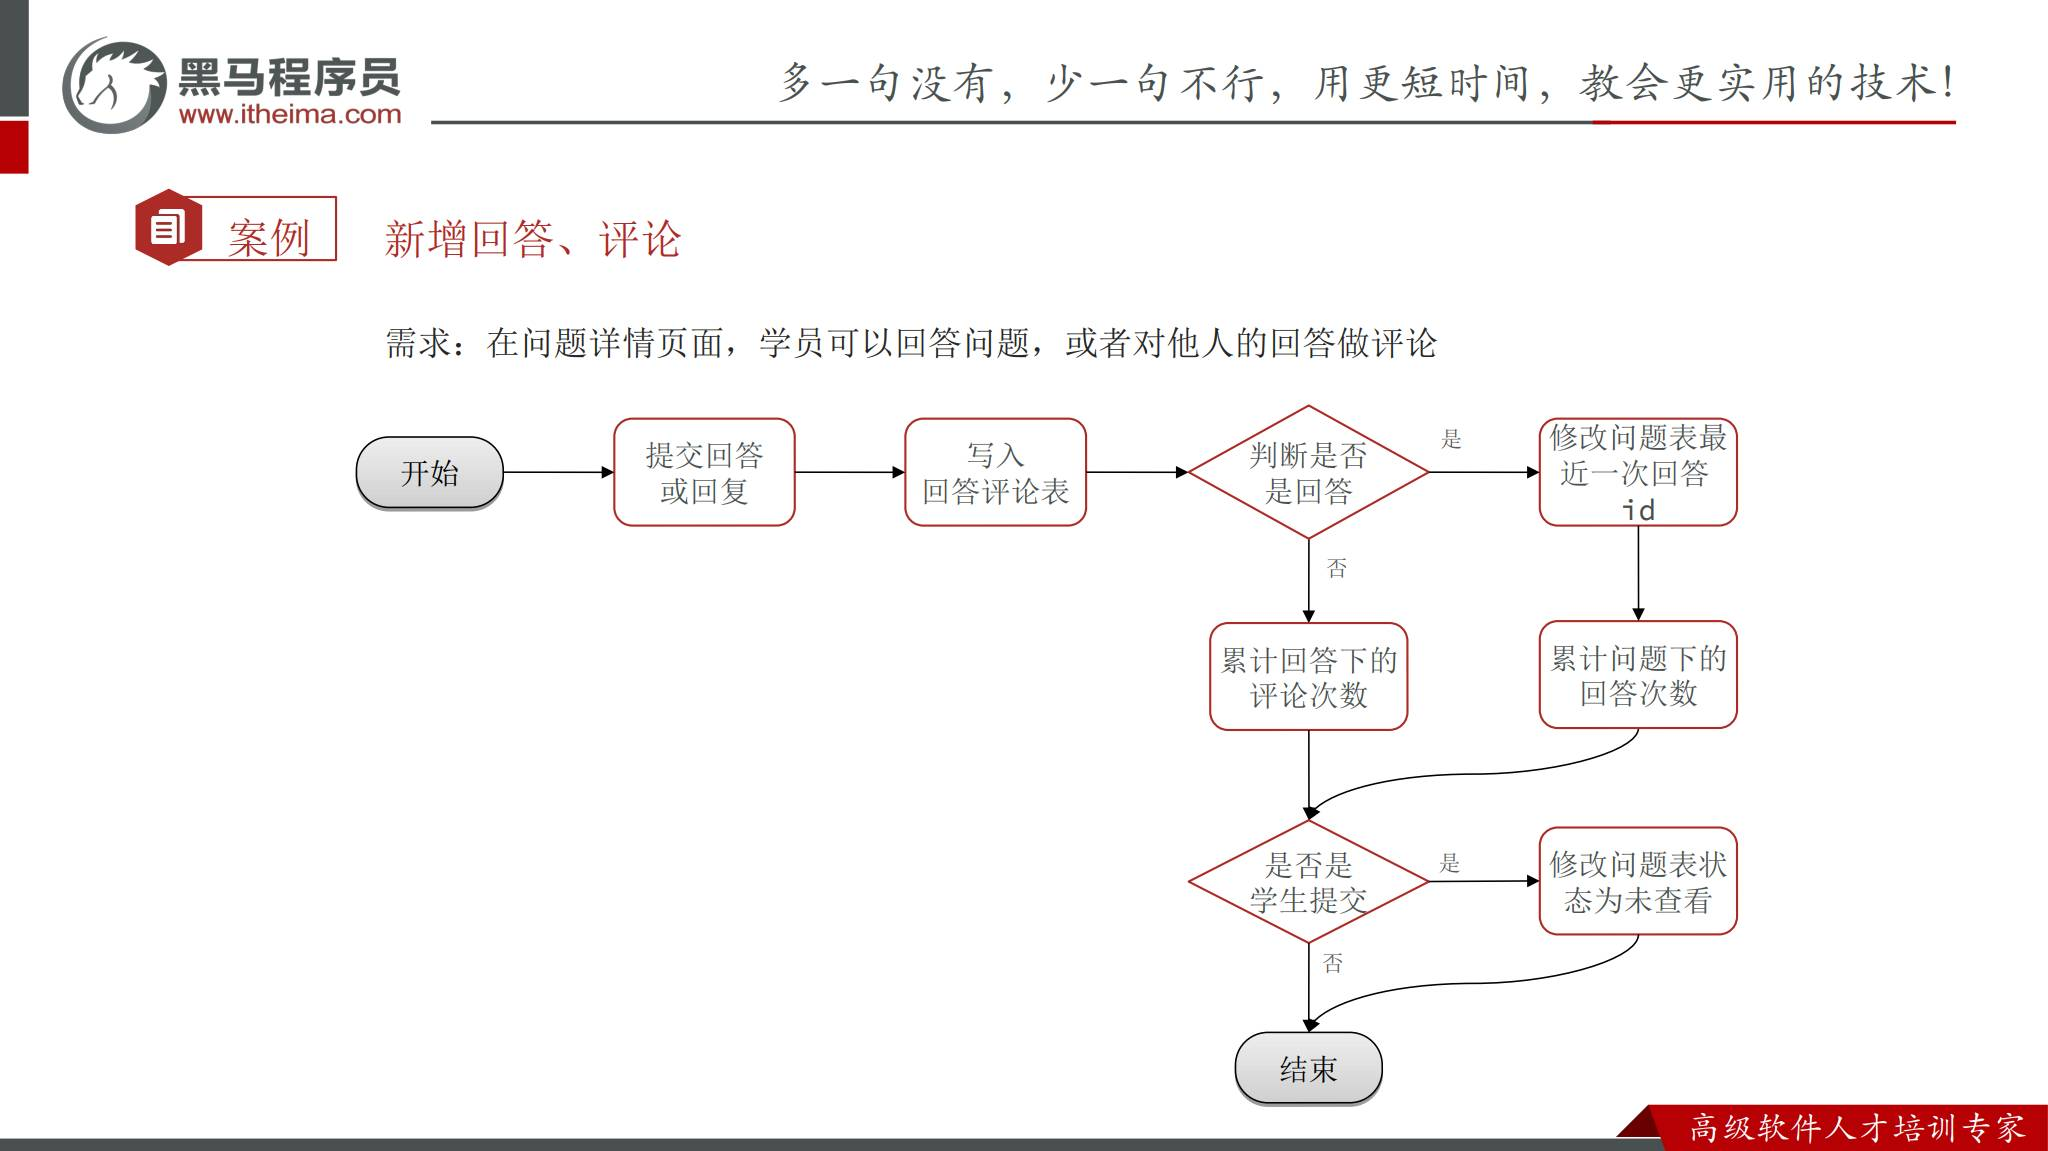

| 本次写入 | 附加更新 |
| --- | --- |
| 一级回答 | 问题 `latest_answer_id` 更新为新回答 id，`answer_times + 1` |
| 二级评论 | 所属一级回答 `reply_times + 1` |
| 学员提交任一种回复 | 问题 status 重置为未查看 |
| 老师提交回复 | 不按学员规则重置查看状态 |

所有计数指的是对应层级：评论不能增加问题的回答数；回复评论仍应累计到根回答的评论数。


## 回复写入事务与原子计数

回复插入成功但计数更新失败，会使列表与实际记录不一致。新增回复、累计数量、维护最新回答指针、重置查看状态应在同一个数据库事务里完成。

**补充 / 练习实现示例**：以下 SQL 展示分支，不是课程提供的完整实现。

```sql
BEGIN;
-- 校验并按统一规则锁定父问题；评论还需校验所属回答
INSERT INTO interaction_reply
    (id, question_id, answer_id, user_id, content,
     target_user_id, target_reply_id, anonymity)
VALUES
    (:replyId, :questionId, :answerId, :currentUserId, :content,
     :targetUserId, :targetReplyId, :anonymity);

-- 一级回答分支
UPDATE interaction_question
SET latest_answer_id = :replyId, answer_times = answer_times + 1
WHERE id = :questionId;

-- 评论分支：与上面的一级回答分支二选一
UPDATE interaction_reply
SET reply_times = reply_times + 1
WHERE id = :answerId AND question_id = :questionId AND answer_id = 0;

-- 仅当服务端确认提交者为学员
UPDATE interaction_question SET status = 0 WHERE id = :questionId;
COMMIT;
```

使用 `count = count + 1` 让数据库执行原子自增，避免多个请求读到相同旧数后互相覆盖；每次更新还要检查目标是否存在及受影响行数。

**补充**：网络重试仍可能重复插入。需要请求幂等键等机制，确保同一提交只新增一次并计数一次。雪花主键本身不能阻止两次请求生成两个不同 id。

并发回答还要定义“最新”的顺序：提交时间、创建时间或事务顺序。不能无条件用最后执行更新的旧请求覆盖较新回答指针；需要串行协调或排序条件。


## 回复关系与角色校验

回复 DTO 可以被修改，不能仅凭 questionId、answerId、targetUserId 相信它们都合法。

| 校验 | 防止的问题 |
| --- | --- |
| 问题存在，课程访问权限有效 | 向不存在或无权访问的问题提交 |
| answerId 是该问题下的一级回答 | 把评论挂到其他问题或某条二级评论下面 |
| targetReplyId 属于同一问题、同一回答讨论 | 跨讨论串伪造目标 |
| targetUserId 与目标回复作者一致 | 伪造“回复了谁”，泄露或误用身份 |
| 当前 userId 取自 UserContext | 冒充其他作者 |
| isStudent 由可信身份核验 | 绕过未查看提醒或冒充老师 |
| 内容及匿名字段有效 | 空内容、超长内容、异常参数 |

**改进思路**：根据目标回复在服务端计算其作者 id，再规范化所属根回答；客户端的 targetUserId 只作提示，不能作为最终事实。若目标作者匿名，还要确保响应不会回显真实目标用户 id。

对于隐藏问题或回答，是否允许继续写入应有统一产品规则。课程要求用户端看不到隐藏内容，通常用户端也不应通过直接请求继续写入；管理端按管理权限处理。


## 分页查询回答与评论

回答可能很多，评论也可能很多，页面用滚动加载更多，后端仍是分页查询；不必每次查询整棵回复树。

```text
GET /ls/replies/page?pageNo=1&pageSize=5&questionId=100
GET /ls/replies/page?pageNo=1&pageSize=5&answerId=201
```

| 目标 | 核心过滤 | 返回特有内容 |
| --- | --- | --- |
| 问题下的回答 | question_id = Q，answer_id = 0 | 回答下的评论数 |
| 回答下的评论 | answer_id = A | 目标用户昵称，无需展示更深层评论数 |

**补充查询示例**：

```sql
-- 用户端一级回答：父问题的可见性也必须先检查
SELECT id, question_id, answer_id, content, user_id,
       anonymity, reply_times, liked_times, create_time
FROM interaction_reply
WHERE question_id = :questionId AND answer_id = 0 AND hidden = b'0'
ORDER BY create_time DESC, id DESC
LIMIT :offset, :pageSize;

-- 用户端二级评论：所属问题、一级回答都须可见
SELECT id, content, user_id, anonymity, target_reply_id,
       target_user_id, liked_times, create_time
FROM interaction_reply
WHERE answer_id = :answerId AND hidden = b'0'
ORDER BY create_time DESC, id DESC
LIMIT :offset, :pageSize;
```

讲义参数要求 questionId 与 answerId 至少一个有值。若两个都有，应验证 answer 属于该问题；不能简单同时加条件后把不合法关系解释成正常空列表。

**课件要求**：默认按点赞数排序，并返回当前用户是否点赞以高亮按钮；本章因点赞暂未实现，这两项先不实现。上面示例采用时间排序，后续切换可用 `liked_times DESC, id DESC` 保证顺序确定。


## 回复 VO：匿名目标、统计与管理端差异

用户端回复列表需要内容、作者资料、时间、点赞数；回答需要评论数，评论需要目标昵称。实现时复用批量加载思路，避免每条再查作者和目标。

```text
分页查回复 → 收集非匿名作者id
          → 收集目标回复id → 批量查目标回复并判断匿名
          → 合并可展示目标作者id → 批量查询用户 → 组装VO
```

| 规则 | 用户端 `/replies/page` | 管理端 `/admin/replies/page` |
| --- | --- | --- |
| 隐藏内容 | 不返回；检查父问题、父回答 | 按管理权限返回，并提供 hidden |
| 匿名作者 | 清理身份字段 | 课程规则允许查看真实作者 |
| 匿名目标 | 不泄露目标昵称或 id | 按管理权限处理 |
| 评论数量 | 不计入隐藏评论 | 包含隐藏评论 |
| 用户类型 | 按页面需要 | 原型要求区分老师、学员等类型 |

这里的权限不同，所以不能仅靠一个客户端传来的“admin=true”参数复用接口。可以在服务内部复用查询、批量映射工具，由经过授权的入口传入展示策略。

讲义 DDL 只有一列 reply_times，若它保存总评论数，就不能直接作为用户端可见评论数。**补充**可以对本页回答执行一次分组统计：

```sql
SELECT answer_id, COUNT(*) AS visible_reply_times
FROM interaction_reply
WHERE answer_id IN (:answerIds) AND hidden = b'0'
GROUP BY answer_id;
```

映射回每个回答，没有统计项时补 0。若需要维护独立的可见计数，则新增、删除、隐藏和恢复时都要同步维护。


## 隐藏与恢复：父级可见性不能遗漏

管理端隐藏接口修改 hidden 字段，但“隐藏问题后它的所有回复不可见”不能只靠问题列表的过滤实现。直接访问详情或评论接口也必须守住规则。

**补充定义**：

```text
问题可见 = !question.hidden
回答可见 = !question.hidden && !answer.hidden
评论可见 = !question.hidden && !answer.hidden && !comment.hidden
```

| 实现方式 | 优点 | 代价 |
| --- | --- | --- |
| 查询时检查祖先，保留每条记录自己的 hidden | 隐藏父级立刻整体生效；恢复父级不会解除子项独立隐藏 | 每个入口都必须检查完整上下文 |
| 隐藏父级时批量更新子项 hidden | 查询自身字段简单 | 恢复时容易把此前独立隐藏的子项也恢复 |

课程强调隐藏回答时下面评论也要隐藏。这是用户可见性的要求；可以用第一种方式满足，也可以设计清楚隐藏来源后做批量更新。

**反例**：评论 C 因违规已单独 hidden=true，后来隐藏再恢复它的父回答 A；如果恢复 A 时无条件将全部评论置 false，C 会被错误公开。

隐藏与删除还会影响问题的最新回答预览、可见回答数、可见评论数。必须统一定义统计口径，而不只改一个布尔值。


## 冗余统计与跨服务一致性

answer_times、reply_times、latest_answer_id 都能由回复记录推导，却被存储以加速展示。维护它们时要考虑整个生命周期。

| 事件 | 需要处理 |
| --- | --- |
| 新增回答 | 插入回复、回答总数 +1、最新回答指针、学员未查看提醒 |
| 新增评论 | 插入回复、根回答评论总数 +1、学员未查看提醒 |
| 隐藏或恢复 | 用户可见统计、最新可见回答预览；总统计按定义保持或更新 |
| 删除问题 | 问题、回复以及后续关联数据一并处理 |
| 删除回复的扩展功能 | 调整对应计数与最新指针，处理失效目标引用 |

**补充**：定期按回复表做校验或重建统计，可以修复历史异常。若隐藏不减少总数，则用户端显示可见数、管理端显示总数要明确区分。

数据库事务只保证学习服务数据库里的相关写入，不会把用户、课程、搜索服务的远程调用一起纳入同一个本地事务。分页数据补齐不是所有服务的同一时刻快照，应允许名称缺失、资料已删除等情况。

对于隐私字段和隐藏内容，降级也必须继续遵守可见规则，不能在远程服务失败时直接返回未经清理的 PO。


## 材料差异与实现时核对项

| 材料中的差异或遗漏 | 本笔记的处理 |
| --- | --- |
| 分页返回字段：PPT 有 `pages/items`，后面又有 `pages/list`；在线示例是 `totalPage/list` | 以实际 `PageDTO` 序列化结果和前端契约核对，不能混拼成新格式 |
| 修改表单：PPT 列课程章节，在线讲义只修改标题、详情、匿名 | 区分编辑字段白名单 |
| 原型章节可选，DDL chapter_id / section_id 不可空 | 明确 NULL 或 0 的统一存储规则 |
| 用户分页小节条件与文字“章节筛选”不完全对应 | 若需要章筛选，新增明确契约 |
| 管理分页文字一处写“所有匿名信息展示”，另一处沿用“匿名不展示头像昵称” | 按总体管理规则和最终实现理解：授权管理端可以看真实作者 |
| 管理分页声明中曾出现 `queryQuestionsPageForAdmin`，最终实现用 `queryQuestionPageAdmin` | 接口声明、控制器调用与实现方法名保持一致 |
| 用户详情没有清空匿名 userId；最新回答没有过滤 hidden | 在改进示例中明确修正 |
| Caffeine 配置注释将条目数误称内存限制 | 按 API 真实含义解释 |
| CategoryCache 未直接读取 Redis | 不把理论多级缓存写成课程已实现 |
| 评论章节代码实现为空或留作练习 | 给出明确标注的设计与练习示例 |

本章不把附带 SQL 文件中的样例数据、DTO 校验注解或 VO 的完整字段当作已读到的源码。实际项目实现时应与附件和现有前后端代码逐项对齐。


## 业务验证场景

问答系统表面上是 CRUD，真正容易错的是权限、匿名、层级和冗余数据。本章的验证重点应针对这些边界。

| 场景 | 应看到的结果 |
| --- | --- |
| 课程详情页未选章节提问 | 按统一存储约定成功，视频页提问正确关联小节 |
| 查看我的问题 | 按登录用户过滤，匿名不影响自己的操作权限 |
| 非作者修改、删除 | 拒绝，数据未改变 |
| 匿名问题与匿名回答 | 列表、详情、目标昵称均不泄露真实身份字段 |
| 两个回答，多个评论相互回复 | 每条评论都归属正确根回答，目标与作者一致 |
| 学员新回复与老师回复 | 仅学员新互动按规则重置查看状态 |
| 隐藏父问题或父回答后直接访问子接口 | 用户端仍看不到隐藏讨论 |
| 恢复父回答 | 原本单独隐藏的评论继续隐藏 |
| 最新回答隐藏、删除，或作者数据缺失 | 不泄露内容，不抛空指针，预览按策略返回 |
| 搜索课程名没有匹配 | 返回空页，不意外查全部问题 |
| 批量接口部分资料缺失 | 主列表可按约定降级，隐私规则仍有效 |
| 并发回复、重试与删除竞争 | 无孤儿记录、重复计数或不一致指针 |
| 分类缓存命中、过期、更新 | 回源与名称映射正常，所有实例按约定更新 |

性能上检查一页查询的 SQL 数量、远程调用次数、p95 / p99 耗时、批量 id 数量、缓存命中率及回源失败。不能只用“加了缓存”“用了批量查询”替代实际结果。


## 面试提示与章节衔接

本章建立讨论内容与作者关系，下一章将实现回答、评论的点赞与取消点赞，再处理高频操作的缓存与消息方案。

**面试提示**：先讲为什么这样建模，再讲怎样查询与保证业务规则。

> 问答系统把问题独立存储，回答和评论统一放在回复表。一级回答用 answerId=0，二级评论都记录同一个根回答 id，再用 targetReplyId 表示具体回复目标，这样逻辑上可以继续对话，界面只展示两层。问题分页后批量查最新回答、合并非匿名用户 id，再一次调用用户服务，避免逐条远程查询。管理端根据课程名称先查课程 id，再查询问题并补齐课程、章节和分类；分类量小、变化少，用 Caffeine 本地缓存。实现时重点处理匿名身份清理、父级隐藏传播、原子计数和事务，避免只完成基本 CRUD 而遗漏业务规则。

| 追问 | 回答要点 |
| --- | --- |
| 为什么不是两张“回答表、评论表”？ | 公共字段多，统一表配合 answerId 区分，减少重复逻辑 |
| 为什么还需要 targetReplyId？ | answerId 只标明所属讨论，targetReplyId 标明直接对话目标 |
| 什么是反范式的代价？ | 最新回答与计数查询快，但写入、隐藏、删除都需要维护一致性 |
| N+1 如何处理？ | 一页先收集 id，批量查询并建 Map，空集合跳过 |
| 匿名是否只是不查昵称？ | 还要清理真实 id、头像，以及目标回复透露的身份 |
| Caffeine 与 Redis 怎么选？ | 小而低频变化的数据适合本地；共享与更大容量考虑 Redis，多级缓存仍需一致性策略 |
| maximumSize 是内存限制吗？ | 它限制条目数；一个条目中的大 Map 仍会占用大量内存 |
| 事务能保证什么？ | 同一数据库内回复与计数一起成功；远程服务、并发查看和隐私规则需另行处理 |
